<a href="https://colab.research.google.com/github/Anikettcoder/ResQVision/blob/feature%2Fdata_preparation/notebooks/02_YOLO26_Baseline_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import os

# Main YOLO dataset directory
DATASET_ROOT = (
    "/content/drive/MyDrive/ResQvision/"
    "Datasets/Processed/VisDrone_YOLO"
)

# Dataset configuration file
DATA_YAML_PATH = os.path.join(
    DATASET_ROOT,
    "data.yaml"
)

# Training and validation image directories
YOLO_IMAGES_TRAIN = os.path.join(
    DATASET_ROOT,
    "images",
    "train"
)

YOLO_IMAGES_VAL = os.path.join(
    DATASET_ROOT,
    "images",
    "val"
)

# Training and validation label directories
YOLO_LABELS_TRAIN = os.path.join(
    DATASET_ROOT,
    "labels",
    "train"
)

YOLO_LABELS_VAL = os.path.join(
    DATASET_ROOT,
    "labels",
    "val"
)

print("Dataset root:", DATASET_ROOT)
print("YAML path:", DATA_YAML_PATH)

Dataset root: /content/drive/MyDrive/ResQvision/Datasets/Processed/VisDrone_YOLO
YAML path: /content/drive/MyDrive/ResQvision/Datasets/Processed/VisDrone_YOLO/data.yaml


In [12]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print( "GPU:",  torch.cuda.get_device_name(0))
else:
    print("GPU not available.")

CUDA available: True
GPU: Tesla T4


In [4]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


IMPORTING YOLO26

In [5]:
from ultralytics import YOLO

print("YOLO library imported successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO library imported successfully.


Verify Dataset yaml Path

In [6]:
print("Dataset YAML path:")
print(DATA_YAML_PATH)

print("\nYAML file exists:")
print(os.path.isfile(DATA_YAML_PATH))

Dataset YAML path:
/content/drive/MyDrive/ResQvision/Datasets/Processed/VisDrone_YOLO/data.yaml

YAML file exists:
False


In [7]:
import os

# Your verified processed YOLO dataset folder
DATASET_ROOT = (
    "/content/drive/MyDrive/ResQVision/"
    "Datasets/Processed/VisDrone_YOLO"
)

# Create the complete path to data.yaml
DATA_YAML_PATH = os.path.join(
    DATASET_ROOT,
    "data.yaml"
)

print("Dataset YAML path:")
print(DATA_YAML_PATH)

print("\nYAML file exists:")
print(os.path.isfile(DATA_YAML_PATH))

Dataset YAML path:
/content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/data.yaml

YAML file exists:
True


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")                                                        # yolo26n.pt → pretrained YOLO26 nano checkpoint

print("YOLO26 model loaded successfully.")

YOLO26 model loaded successfully.


In [ ]:
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [ ]:
!nvidia-smi

Fri Sep 25 13:47:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

YOLO26 Training Started

In [8]:
OUTPUT_DIR = ("/content/drive/MyDrive/ResQVision/Outputs")

In [ ]:
results = model.train(
    data=DATA_YAML_PATH,
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    patience=15,

    project=OUTPUT_DIR,
    name="yolo26n_visdrone_baseline",

    pretrained=True,
    save=True,
    plots=True
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

In [ ]:
from ultralytics import YOLO

model_m= YOLO("yolo26m.pt")                                                        # yolo26n.pt → pretrained YOLO26 nano checkpoint

print("YOLO26 model loaded successfully.")

YOLO26 model loaded successfully.


In [ ]:
results = model_m.train(
    data=DATA_YAML_PATH,
    epochs=50,
    imgsz=800,
    batch=8,
    device=0,
    patience=20,

    project=OUTPUT_DIR,
    name="yolo26m_visdrone_baseline",

    pretrained=True,
    save=True,
    plots=True
)

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m_visdr

In [14]:
from ultralytics import YOLO

best_model = YOLO(
    "/content/drive/MyDrive/ResQVision/Outputs/yolo26m_visdrone_baseline/weights/best.pt"
)

print("Best YOLO26m model loaded successfully!")

Best YOLO26m model loaded successfully!


In [13]:
import os

search_root = "/content/drive/MyDrive/ResQVision"

yaml_files = []

for root, dirs, files in os.walk(search_root):
    # Avoid scanning unnecessary hidden/system folders
    dirs[:] = [d for d in dirs if d not in [" .ipynb_checkpoints"]]

    if "data.yaml" in files:
        yaml_files.append(os.path.join(root, "data.yaml"))

print("YAML files found:", len(yaml_files))

for path in yaml_files:
    print(path)

KeyboardInterrupt: 

In [12]:
# Select the VisDrone YOLO dataset YAML
candidates = [
    p for p in yaml_files
    if "visdrone_yolo" in p.lower()
]

if len(candidates) == 1:
    DATA_YAML_PATH = candidates[0]
    print("Correct YAML path:", DATA_YAML_PATH)

elif len(candidates) > 1:
    print("Multiple matching YAML files found:")
    for i, path in enumerate(candidates):
        print(i, path)

else:
    print("No VisDrone YOLO YAML file found.")

NameError: name 'yaml_files' is not defined

In [10]:
import yaml
import os

# Read your existing dataset YAML
with open(DATA_YAML_PATH, "r") as file:
    data_config = yaml.safe_load(file)

# Extract validation image path
val_path = data_config["val"]

# Resolve relative paths using the YAML file's directory
if not os.path.isabs(val_path):
    val_path = os.path.join(
        os.path.dirname(DATA_YAML_PATH),
        val_path
    )

VAL_IMAGES_DIR = os.path.normpath(val_path)

# Verify the directory
print("Validation image directory:", VAL_IMAGES_DIR)
print("Directory exists:", os.path.isdir(VAL_IMAGES_DIR))

if os.path.isdir(VAL_IMAGES_DIR):
    print("Number of validation images:",
          len([f for f in os.listdir(VAL_IMAGES_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png'))]))
else:
    print("ERROR: Validation directory not found. Check your data.yaml paths.")

Validation image directory: /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val
Directory exists: True
Number of validation images: 531


In [17]:
results = best_model.predict(
    source=VAL_IMAGES_DIR,
    conf=0.25,
    imgsz=800,
    device=0,
    save=True,
    project=OUTPUT_DIR,
    name="yolo26m_validation_predictions"
)


image 1/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_02999_d_0000005.jpg: 480x800 26 persons, 99.1ms
image 2/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_03499_d_0000006.jpg: 480x800 41 persons, 56.8ms
image 3/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_03999_d_0000007.jpg: 480x800 50 persons, 46.9ms
image 4/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_04527_d_0000008.jpg: 480x800 48 persons, 46.3ms
image 5/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_05249_d_0000009.jpg: 480x800 5 persons, 58.8ms
image 6/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_05499_d_0000010.jpg: 480x800 9 persons, 56.8ms
image 7/531 /content/drive/MyDrive/ResQVision/Datasets/Processed/VisDrone_YOLO/images/val/0000001_05999_d_0000011.jpg: 480x80

Total prediction images: 531


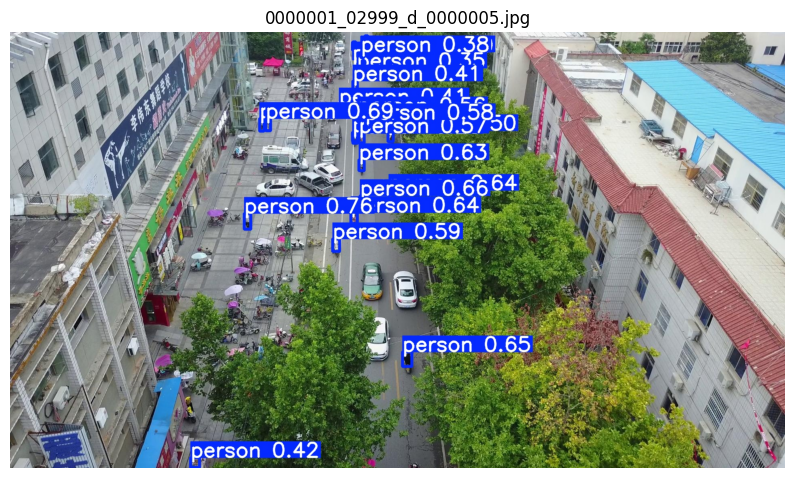

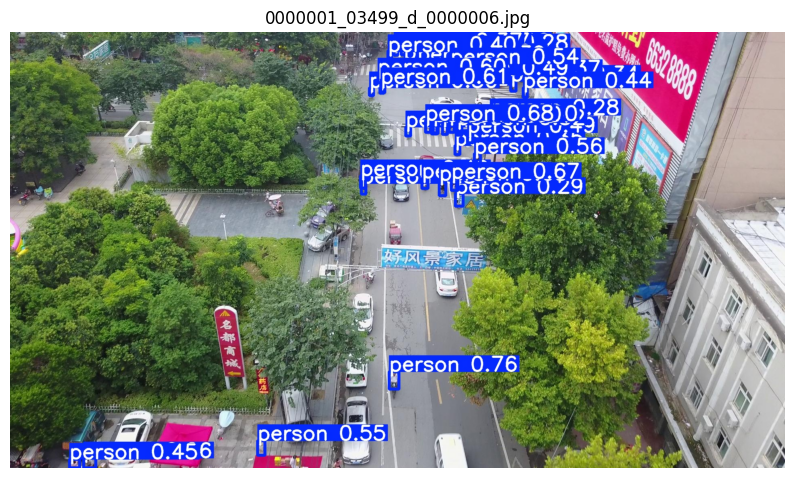

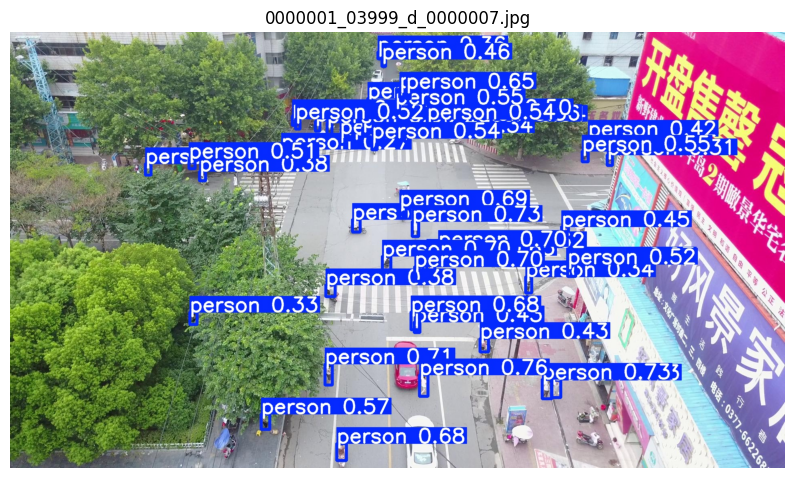

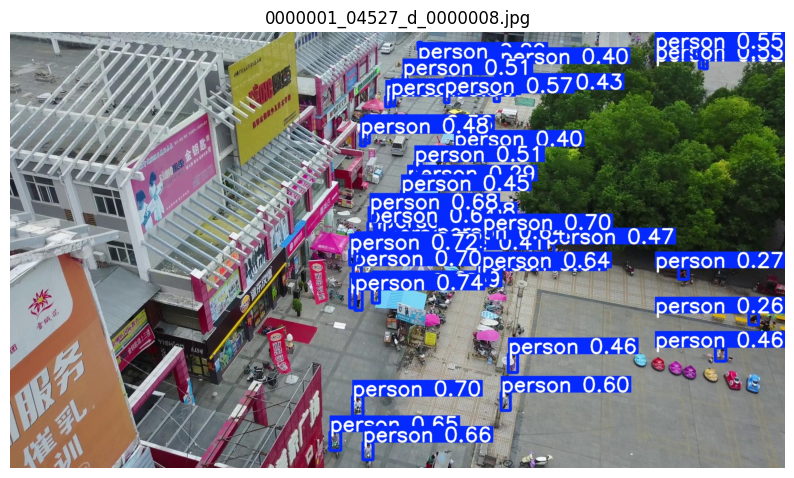

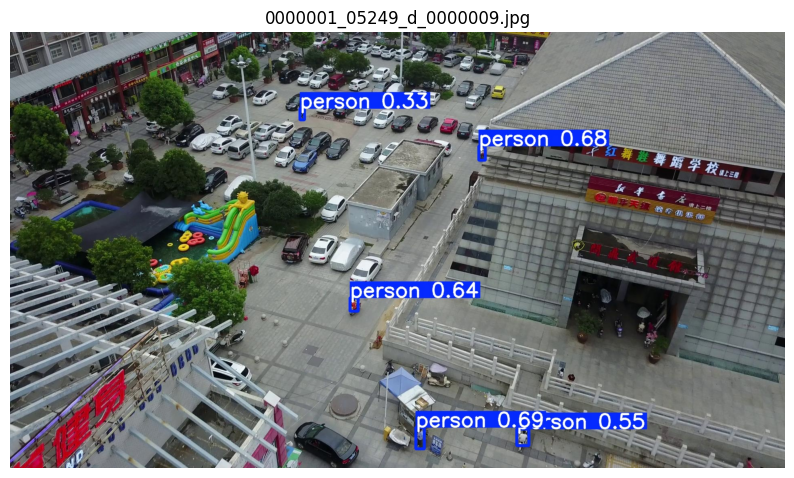

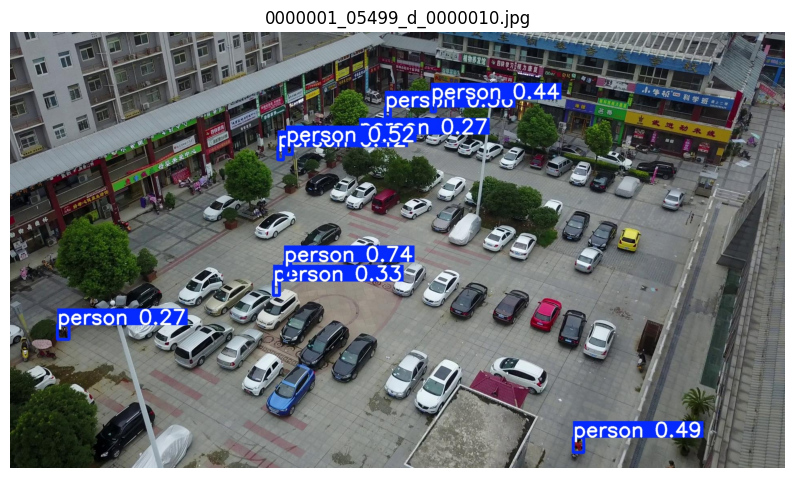

In [18]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

PREDICTION_DIR = (
    "/content/drive/.shortcut-targets-by-id/"
    "1veZlm3z_nyxTYdHKIbIloEQ2MazRgQbo/"
    "ResQVision/Outputs/yolo26m_validation_predictions"
)

image_files = []

for ext in ["*.jpg", "*.jpeg", "*.png"]:
    image_files.extend(
        glob.glob(os.path.join(PREDICTION_DIR, ext))
    )

print("Total prediction images:", len(image_files))

# Display first 6 predictions
for image_path in image_files[:6]:

    img = Image.open(image_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.title(os.path.basename(image_path))
    plt.axis("off")
    plt.show()